# ДЗ №2. Семантическая сегментация кожных поражений

**Источник данных:** [Dataset Ninja — Skin Cancer: HAM10000](https://datasetninja.com/skin-cancer-ham10000) (версия с масками Supervisely).

**Задача:** самостоятельно реализовать **одну** компактную архитектуру сегментации (encoder–decoder со skip-связью), обучить её как минимум **дважды** при изменении одного параметра и сравнить результаты.

В блокноте уже подготовлены чтение изображений и разметки, формирование фиксированных выборок, `Dataset`, `DataLoader` и визуальная проверка данных. **Реализацию архитектуры, обучение, вычисление метрики и экспериментальное сравнение выполняете самостоятельно.**

Полное условие и критерии: [страница домашнего задания](https://ai-mai-307.github.io/ml-dl-course-site/courses/deep-learning/2026-fall/assignments/hw-02/).

## 1. Скачивание и распаковка датасета

1. Откройте [Skin Cancer: HAM10000 — Dataset Ninja](https://datasetninja.com/skin-cancer-ham10000), выберите **Download** для **полного архива Supervisely** (около 2,6 ГБ). Обычный HAM10000 без аннотаций и **Download Sample** не подходят для итоговых экспериментов.
2. Распакуйте архив в каталог `data/` рядом с `solution.ipynb`. Пример из PowerShell в папке с ноутбуком:

   ```powershell
   New-Item -ItemType Directory -Force data
   tar -xf "ИМЯ_СКАЧАННОГО_АРХИВА.tar" -C data
   ```

   Не переименовывайте файлы внутри архива. Если после распаковки возникли дополнительные вложенные папки, изменять их структуру не нужно: следующий код рекурсивно найдёт `img/` и `ann/`.
3. Установите зависимости в используемое Python-окружение (если их ещё нет):

   ```powershell
   python -m pip install torch numpy pandas pillow matplotlib scikit-learn
   ```

Файл `dataset_meta_comp.csv` **не нужен**: таблица `ds_df` и разбиение создаются автоматически. При запуске Jupyter текущая рабочая папка должна совпадать с папкой, где лежат `solution.ipynb` и `data/`.

## 2. Импорт библиотек и фиксированные параметры

In [1]:
import base64
import io
import json
import random
import zlib
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset


def set_random_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


SEED = 42
set_random_seeds(SEED)

DATA_DIR = Path("../data")
IMAGE_SIZE = (96, 128)       # (H, W); фиксируется для обоих экспериментов
MAX_TRAIN_PER_CLASS = 120    # фиксируется для обоих экспериментов
MAX_VAL_PER_CLASS = 30      # фиксируется для обоих экспериментов
BATCH_SIZE = 4              # одинаковый на CPU и GPU
NUM_WORKERS = 0             # без дополнительных процессов (удобно для Windows)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MIN_EPOCHS = 8              # минимальное число эпох для КАЖДОГО запуска
M_MIN = 0.05               # минимальная val mIoU для базовой модели
MIN_TRAIN_LOSS_DROP = 0.20 # средний train loss: последние 3 эпохи против первых 3

print(f"PyTorch {torch.__version__} | Устройство: {DEVICE}")
print(f"Папка данных: {DATA_DIR.resolve()}")

PyTorch 2.14.1+cu126 | Устройство: cuda
Папка данных: F:\scripts\university projects\AI_mai\Fall_2026\HW2\HandmadeConvEnc-Dec\data


## 3. Таблица изображений и метаданных

В архиве Dataset Ninja отсутствуют собственные `train/val`-метки и файл метаданных. Здесь мы находим JSON-аннотации в формате Supervisely, восстанавливаем имена файлов и список классов.

Два изображения без bitmap-разметки исключаются. Валидация построена как **воспроизводимое стратифицированное разбиение по классу изображения**.

In [2]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Не найдена папка {DATA_DIR.resolve()}. Сначала распакуйте архив Dataset Ninja в data/."
    )

annotation_files = sorted(DATA_DIR.rglob("ann/*.json"))
if not annotation_files:
    raise FileNotFoundError(
        f"В {DATA_DIR.resolve()} не найдены ann/*.json. "
        "Проверьте, что скачан архив Supervisely (с аннотациями), а не исходный HAM10000."
    )

rows = []
ignored_without_bitmap = 0
missing_images = []
for ann_path in annotation_files:
    with ann_path.open("r", encoding="utf-8") as f:
        ann = json.load(f)

    objects = [obj for obj in ann.get("objects", []) if obj.get("bitmap")]
    if not objects:
        ignored_without_bitmap += 1
        continue

    # Имена файлов Supervisely: ISIC_....jpg и ISIC_....jpg.json
    img_name = ann_path.name.removesuffix(".json")
    img_path = ann_path.parent.parent / "img" / img_name
    if not img_path.is_file():
        missing_images.append(str(img_path))
        continue

    class_titles = [obj["classTitle"] for obj in objects]
    class_name = Counter(class_titles).most_common(1)[0][0]
    rows.append({
        "img_name": img_name,
        "ann_name": ann_path.name,
        "class_name": class_name,
        "img_path": img_path,
        "ann_path": ann_path,
    })

if missing_images:
    raise FileNotFoundError(
        f"Для {len(missing_images)} аннотаций не найдены изображения. "
        f"Первое: {missing_images[0]}"
    )
if not rows:
    raise ValueError("Не найдено ни одного изображения с bitmap-аннотацией.")

ds_df = pd.DataFrame(rows).sort_values("img_name").reset_index(drop=True)

# Порядок по алфавиту соответствует исходной таблице преподавателя:
# 1=actinic keratoses, 2=basal cell carcinoma, 3=benign keratosis-like lesions,
# 4=dermatofibroma, 5=melanocytic nevi, 6=melanoma, 7=vascular lesions.
CLASS_NAMES = sorted(ds_df["class_name"].unique(), key=str.casefold)
CLASS_TO_INDEX = {name: idx + 1 for idx, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES) + 1  # ещё один класс — фон = 0

if NUM_CLASSES != 8:
    raise ValueError(
        f"Ожидались 7 диагностических классов и фон, получено: {CLASS_NAMES}. "
        "Если скачан только Sample, проверьте полный архив."
    )

ds_df["class_index"] = ds_df["class_name"].map(CLASS_TO_INDEX).astype(int)
print(f"Изображений с масками: {len(ds_df)}; без bitmap: {ignored_without_bitmap}")
print("Классы: 0 — фон")
for name, index in CLASS_TO_INDEX.items():
    print(f"  {index} — {name}")
display(ds_df[["img_name", "class_name", "class_index"]].head())

Изображений с масками: 10013; без bitmap: 2
Классы: 0 — фон
  1 — actinic keratoses
  2 — basal cell carcinoma
  3 — benign keratosis-like lesions
  4 — dermatofibroma
  5 — melanocytic nevi
  6 — melanoma
  7 — vascular lesions


,img_name,class_name,class_index
0,ISIC_0024306.jpg,melanocytic nevi,5
1,ISIC_0024307.jpg,melanocytic nevi,5
2,ISIC_0024308.jpg,melanocytic nevi,5
3,ISIC_0024309.jpg,melanocytic nevi,5
4,ISIC_0024310.jpg,melanoma,6


In [3]:
train_df, val_df = train_test_split(
    ds_df,
    test_size=0.20,
    stratify=ds_df["class_index"],
    random_state=SEED,
)
train_df = train_df.copy().assign(split="train")
val_df = val_df.copy().assign(split="val")
ds_df = pd.concat([train_df, val_df], ignore_index=True)

assert set(train_df["img_path"]).isdisjoint(set(val_df["img_path"]))


def limit_per_class(frame, maximum):
    if maximum is None:
        return frame.sort_values("img_name").reset_index(drop=True)
    indices = []
    for _, group in frame.groupby("class_index"):
        n = min(len(group), maximum)
        indices.extend(group.sample(n=n, random_state=SEED).index.tolist())
    return frame.loc[indices].sort_values("img_name").reset_index(drop=True)


train_used = limit_per_class(train_df, MAX_TRAIN_PER_CLASS)
val_used = limit_per_class(val_df, MAX_VAL_PER_CLASS)
print(f"Train: {len(train_df)} всего, {len(train_used)} используются")
print(f"Val:   {len(val_df)} всего, {len(val_used)} используются")
print("Валидационные классы:", val_used["class_index"].value_counts().sort_index().to_dict())
assert val_used["class_index"].nunique() == NUM_CLASSES - 1, "В val представлены не все семь классов"
assert train_used["class_index"].nunique() == NUM_CLASSES - 1, "В train представлены не все семь классов"
assert set(train_used["img_path"]).isdisjoint(set(val_used["img_path"]))

Train: 8010 всего, 806 используются
Val:   2003 всего, 201 используются
Валидационные классы: {1: 30, 2: 30, 3: 30, 4: 23, 5: 30, 6: 30, 7: 28}


## 4. Преобразование Supervisely-масок и `Dataset`

Разметка хранится как `base64 → zlib → PNG` вместе со смещением `bitmap.origin`. Область объекта извлекается из **альфа-канала** PNG. Изображение масштабируется билинейно, маска — методом ближайшего соседа, чтобы индексы классов не смешивались.

`SkinCancerDataset[i]` возвращает тройку `(image, mask, class_index)`:

- `image`: `torch.float32`, форма `[3, H, W]`, нормировка в `[-1, 1]`;
- `mask`: `torch.int64`, форма `[H, W]`, метки `0..7` (`0` — фон);
- `class_index`: диагностический класс изображения (1–7).

Изображения и маски читаются **по требованию**: весь архив вряд ли поместится в оперативную память.

In [4]:
def decode_supervisely_bitmap_to_binary(mask_data_b64):
    raw = base64.b64decode(mask_data_b64)
    try:
        raw = zlib.decompress(raw)
    except zlib.error:
        # На случай, если данные уже содержат PNG без zlib-сжатия.
        pass
    with Image.open(io.BytesIO(raw)) as bitmap_image:
        rgba = np.asarray(bitmap_image.convert("RGBA"))
    return (rgba[..., 3] > 0).astype(np.uint8)


class SkinCancerDataset(Dataset):
    def __init__(self, frame, image_size=IMAGE_SIZE):
        self.frame = frame.reset_index(drop=True)
        self.image_size = image_size  # (H, W)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        h, w = self.image_size

        with Image.open(row["img_path"]) as img:
            img = img.convert("RGB")
            original_w, original_h = img.size
            img = img.resize((w, h), resample=Image.Resampling.BILINEAR)
            img_array = np.asarray(img).copy()

        image = torch.from_numpy(img_array).permute(2, 0, 1).float() / 255.0
        image = (image - 0.5) / 0.5

        # Сначала маска в исходном разрешении, потом NEAREST-resize.
        full_mask = np.zeros((original_h, original_w), dtype=np.uint8)
        with Path(row["ann_path"]).open("r", encoding="utf-8") as f:
            annotation = json.load(f)

        for obj in annotation.get("objects", []):
            if not obj.get("bitmap"):
                continue
            class_title = obj["classTitle"]
            class_index = CLASS_TO_INDEX[class_title]
            bitmap = obj["bitmap"]
            small_mask = decode_supervisely_bitmap_to_binary(bitmap["data"])
            x0, y0 = map(int, bitmap["origin"])
            mh, mw = small_mask.shape

            x_start, y_start = max(0, x0), max(0, y0)
            x_end, y_end = min(original_w, x0 + mw), min(original_h, y0 + mh)
            if x_start >= x_end or y_start >= y_end:
                continue

            crop = small_mask[
                y_start - y0 : y_end - y0,
                x_start - x0 : x_end - x0,
            ]
            patch = full_mask[y_start:y_end, x_start:x_end]
            patch[crop > 0] = class_index

        mask_resized = Image.fromarray(full_mask).resize(
            (w, h), resample=Image.Resampling.NEAREST
        )
        mask = torch.from_numpy(np.asarray(mask_resized).copy()).long()
        return image, mask, int(row["class_index"])

## 5. `DataLoader` и проверка данных

В начале **каждого** обучения создавайте загрузчики заново через `make_dataloaders(SEED)` и вызывайте `set_random_seeds(SEED)` **перед созданием модели**. Это позволит корректно сравнить две конфигурации на одинаковом составе данных, с одинаковой инициализацией и порядком батчей.

Следующая ячейка проверяет тензоры одного батча и присутствие **всех семи классов в пиксельных масках `val`**. Проверка может занять некоторое время, так как разметка читается с диска.

In [5]:
train_dataset = SkinCancerDataset(train_used)
val_dataset = SkinCancerDataset(val_used)


def make_dataloaders(seed=SEED):
    train = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    val = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    return train, val


train_loader, val_loader = make_dataloaders()
images, masks, classes = next(iter(train_loader))
print("Изображения:", images.shape, images.dtype)
print("Маски:      ", masks.shape, masks.dtype)
print("Классы:    ", classes.tolist())
print("Метки масок:", torch.unique(masks).tolist())

assert images.shape[1:] == (3, *IMAGE_SIZE)
assert masks.shape[1:] == IMAGE_SIZE and masks.dtype == torch.int64
assert 0 <= masks.min().item() and masks.max().item() < NUM_CLASSES

val_pixel_classes = set()
for _, batch_masks, _ in val_loader:
    val_pixel_classes.update(torch.unique(batch_masks).tolist())

missing_classes = set(range(1, NUM_CLASSES)) - val_pixel_classes
print("Классы, присутствующие в val-масках:", sorted(val_pixel_classes))
assert not missing_classes, f"В пиксельных val-масках отсутствуют классы: {sorted(missing_classes)}"

Изображения: torch.Size([4, 3, 96, 128]) torch.float32
Маски:       torch.Size([4, 96, 128]) torch.int64
Классы:     [1, 2, 4, 6]
Метки масок: [0, 1, 2, 4, 6]
Классы, присутствующие в val-масках: [0, 1, 2, 3, 4, 5, 6, 7]


### Проверка соответствия изображения и маски

Ниже выводятся три изображения **разных диагностических классов**, соответствующие им маски и наложение. Визуально убедитесь, что разметка совпадает с областями поражений, и прокомментируйте замеченные особенности данных.

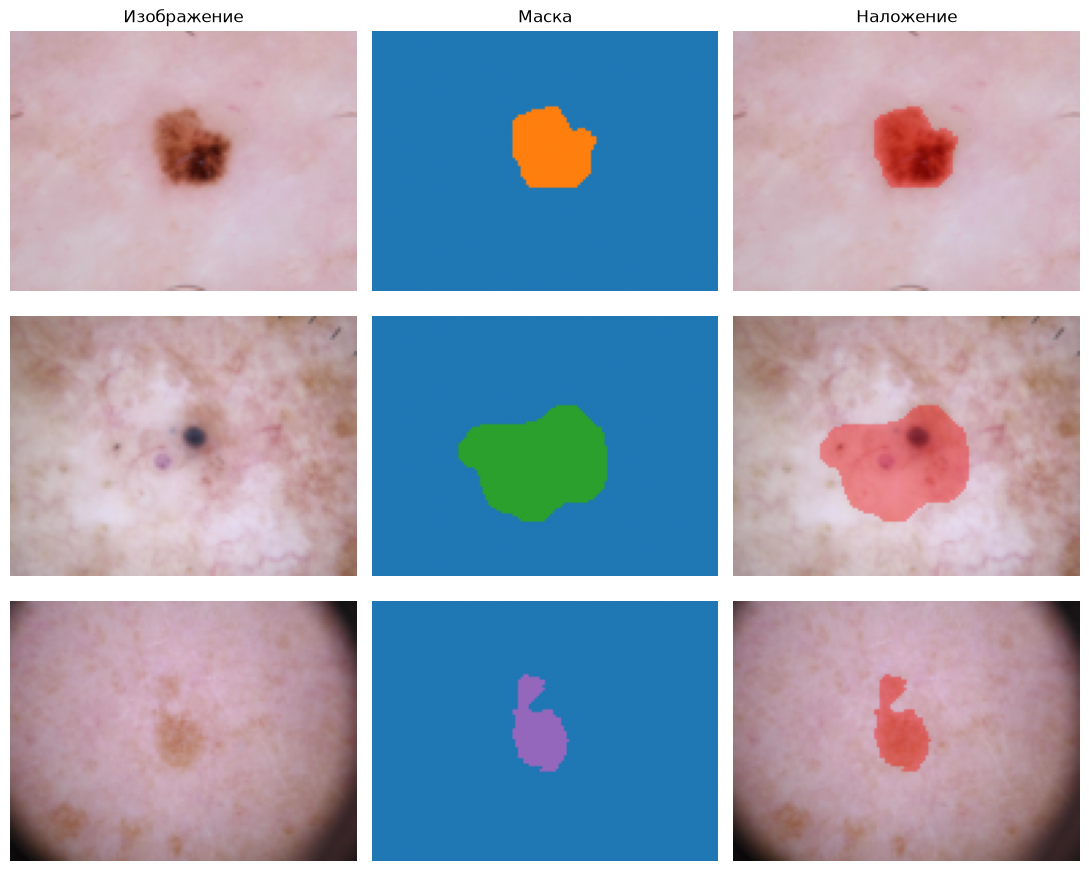

In [6]:
# Берём по одному примеру из трёх разных классов.
example_indices = [
    int(train_used.index[train_used["class_index"] == cls][0])
    for cls in sorted(train_used["class_index"].unique())[:3]
]

fig, axes = plt.subplots(len(example_indices), 3, figsize=(11, 9))
for row_number, example_index in enumerate(example_indices):
    image, mask, class_ind = train_dataset[example_index]
    img = (image * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()
    mask_np = mask.numpy()
    overlay = img.copy()
    overlay[mask_np > 0] = (
        0.65 * overlay[mask_np > 0] + 0.35 * np.array([1.0, 0.0, 0.0])
    )
    axes[row_number, 0].imshow(img)
    axes[row_number, 1].imshow(mask_np, cmap="tab10", vmin=0, vmax=NUM_CLASSES - 1)
    axes[row_number, 2].imshow(overlay)
    axes[row_number, 0].set_ylabel(f"Класс {class_ind}", rotation=90)
    for ax in axes[row_number]:
        ax.axis("off")

for ax, heading in zip(axes[0], ["Изображение", "Маска", "Наложение"]):
    ax.set_title(heading)
plt.tight_layout()
plt.show()

## 6. Самостоятельная реализация модели

**Реализуйте одну собственную компактную архитектуру `encoder–decoder` с хотя бы одной `skip`-связью**. Пользуйтесь базовыми слоями PyTorch (`torch.nn.Conv2d`, `MaxPool2d`, `ConvTranspose2d`, `BatchNorm2d` и т. п.). **Не используйте готовые модели** (`torchvision.models`, `timm`, `segmentation_models_pytorch` и аналоги) **или предобученные веса**.

Для входа `[B, 3, H, W]` выходом должны быть **логиты** `[B, 8, H, W]`. При `nn.CrossEntropyLoss` не вызывайте `softmax` до функции потерь. Кратко опишите выбранную архитектуру, в том числе skip-связь.

In [7]:
def check_model_output_shape(model, example_batch, device=DEVICE):
    """Только проверка интерфейса: саму архитектуру студент реализует отдельно."""
    inputs = example_batch.to(device)
    model = model.to(device)
    model.eval()
    with torch.no_grad():
        logits = model(inputs)
    expected = (inputs.shape[0], NUM_CLASSES, *inputs.shape[-2:])
    assert logits.shape == expected, (tuple(logits.shape), expected)
    assert logits.is_floating_point(), "Модель должна возвращать вещественные логиты"
    print("Размерность выхода корректна:", tuple(logits.shape))


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


class SkinSegmentCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2) # Уменьшение в 2 раза
        self.bottleneck = ConvBlock(32, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(64, 32)

        self.up2 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)

        self.dec2 = ConvBlock(32, 16)

        self.output = nn.Conv2d(16, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        b = self.bottleneck(self.pool(e2))

        d1 = self.up1(b)
        d1 = torch.cat([d1, e2], dim=1)
        d1 = self.dec1(d1)

        d2 = self.up2(d1)
        d2 = torch.cat([d2, e1], dim=1)

        d2 = self.dec2(d2)

        return self.output(d2)
        

## 7. Метрика: Mean Intersection over Union

Реализуйте расчёт mIoU по **семи классам поражений, исключая фон (класс 0)**:

$$
\mathrm{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}, \qquad
\mathrm{mIoU} = \frac{1}{7}\sum_{c=1}^{7}\mathrm{IoU}_c.
$$

**Сначала суммируйте** `TP`, `FP`, `FN` **по всей валидационной выборке**, затем вычисляйте IoU каждого класса. Не усредняйте IoU отдельных батчей. Вычисляйте индексы предсказанных классов через `argmax` по размерности каналов логитов. В блокноте выше проверено наличие пикселей всех семи классов в `val`.

Для самопроверки: если все пиксели предсказаны как фон, то `mIoU = 0`. Это **не считается успешным обучением**.

In [8]:

def update_iou_counts(logits, masks, tp, fp, fn):
    predictions = logits.argmax(dim=1)

    for c in range(1, NUM_CLASSES):
        pred_c = predictions == c
        true_c = masks == c

        tp[c] += (pred_c & true_c).sum().item()
        fp[c] += (pred_c & ~true_c).sum().item()
        fn[c] += (~pred_c & true_c).sum().item()


def compute_miou(tp, fp, fn):
    union = tp[1:] + fp[1:] + fn[1:]

    assert torch.all(union > 0), ("Для одного из классов знаменатель IoU равен нулю")

    iou_per_class = tp[1:] / union
    miou = iou_per_class.mean().item()

    return miou, iou_per_class


@torch.no_grad()
def evaluate_miou(model, dataloader, device=DEVICE):
    model.eval()

    tp = torch.zeros(NUM_CLASSES, dtype=torch.float64)
    fp = torch.zeros(NUM_CLASSES, dtype=torch.float64)
    fn = torch.zeros(NUM_CLASSES, dtype=torch.float64)

    for images, masks, _ in dataloader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)

        update_iou_counts(logits, masks, tp, fp, fn)

    return compute_miou(tp, fp, fn)


## 8. Обучение базовой модели

Самостоятельно реализуйте цикл обучения и валидации. Необходимо:

- обучать с обновлением параметров (`zero_grad → backward → optimizer.step`);
- проверять модель в режиме `eval()` **без обновления весов**;
- сохранять за каждую эпоху `train loss`, `val loss` и **`val mIoU`**;
- провести **не менее 8 эпох**; средний `train loss` за **последние три** эпохи должен быть как минимум **на 20% ниже**, чем за **первые три**;
- получить `val mIoU ≥ 0.05` **для базовой модели** и показать маски, не сводящиеся к одному фону.

Как отправная точка подходят `torch.nn.CrossEntropyLoss()` и `torch.optim.Adam`, но гиперпараметры вы должны выбрать самостоятельно. Модель обязана обучаться даже при отсутствии GPU — уменьшать число изображений или обязательные эпохи нельзя.

**Перед созданием модели и загрузчиков:** повторно вызовите `set_random_seeds(SEED)` и `train_loader, val_loader = make_dataloaders(SEED)`.

In [9]:
set_random_seeds(SEED)
train_loader, val_loader = make_dataloaders(SEED)

NUM_EPOCHS = 100
LEARNING_RATE = 1e-3

model_baseline = SkinSegmentCNN(
    num_classes=NUM_CLASSES
).to(DEVICE)

criterion_baseline = nn.CrossEntropyLoss()

optimizer_baseline = torch.optim.Adam(
    model_baseline.parameters(),
    lr=LEARNING_RATE
)

baseline_config = {
    "architecture": "SkinSegmentCNN",
    "loss": "CrossEntropyLoss",
    "optimizer": "Adam",
    "lr": LEARNING_RATE,
    "epochs": NUM_EPOCHS,
    "batch_size": BATCH_SIZE,
    "seed": SEED
}

history_baseline = {
    "train_loss": [],
    "val_loss": [],
    "val_miou": [],
    "val_foreground_pct": [],
    "val_iou_per_class": []
}

for epoch in range(1, NUM_EPOCHS + 1):
    model_baseline.train()
    train_loss_sum = 0.0
    train_n = 0

    for images, masks, _ in train_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).long()

        optimizer_baseline.zero_grad()

        logits = model_baseline(images)
        loss = criterion_baseline(logits, masks)

        loss.backward()
        optimizer_baseline.step()

        train_loss_sum += loss.item() * images.size(0)
        train_n += images.size(0)

    train_loss = train_loss_sum / train_n

    model_baseline.eval()
    val_loss_sum = 0.0
    val_n = 0

    pred_counts = torch.zeros(
        NUM_CLASSES, dtype=torch.long
    )

    with torch.no_grad():
        for images, masks, _ in val_loader:
            images = images.to(DEVICE)
            masks = masks.to(DEVICE).long()

            logits = model_baseline(images)
            loss = criterion_baseline(logits, masks)

            val_loss_sum += loss.item() * images.size(0)
            val_n += images.size(0)

            predictions = logits.argmax(dim=1)
            pred_counts += torch.bincount(
                predictions.reshape(-1).cpu(),
                minlength=NUM_CLASSES
            )

    val_loss = val_loss_sum / val_n

    val_miou, class_iou = evaluate_miou(
        model_baseline, val_loader, DEVICE
    )

    foreground_pct = (
        100 * pred_counts[1:].sum().item()
        / pred_counts.sum().item()
    )

    history_baseline["train_loss"].append(train_loss)
    history_baseline["val_loss"].append(val_loss)
    history_baseline["val_miou"].append(val_miou)
    history_baseline["val_foreground_pct"].append(foreground_pct)
    history_baseline["val_iou_per_class"].append(
        class_iou.tolist()
    )

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val mIoU: {val_miou:.4f} | "
        f"Foreground: {foreground_pct:.1f}%"
    )

torch.save(
    model_baseline.state_dict(),
    "baseline_model.pth"
)


Epoch 01/100 | Train Loss: 1.3704 | Val Loss: 1.0014 | Val mIoU: 0.0827 | Foreground: 12.0%
Epoch 02/100 | Train Loss: 0.9182 | Val Loss: 0.9165 | Val mIoU: 0.0871 | Foreground: 5.1%
Epoch 03/100 | Train Loss: 0.8510 | Val Loss: 0.8745 | Val mIoU: 0.1131 | Foreground: 12.9%
Epoch 04/100 | Train Loss: 0.8334 | Val Loss: 0.8527 | Val mIoU: 0.1255 | Foreground: 13.8%
Epoch 05/100 | Train Loss: 0.8073 | Val Loss: 0.8505 | Val mIoU: 0.1417 | Foreground: 22.5%
Epoch 06/100 | Train Loss: 0.7917 | Val Loss: 0.8116 | Val mIoU: 0.1246 | Foreground: 16.6%
Epoch 07/100 | Train Loss: 0.7668 | Val Loss: 0.8170 | Val mIoU: 0.1268 | Foreground: 15.3%
Epoch 08/100 | Train Loss: 0.7640 | Val Loss: 0.7956 | Val mIoU: 0.1535 | Foreground: 16.6%
Epoch 09/100 | Train Loss: 0.7579 | Val Loss: 0.8193 | Val mIoU: 0.1630 | Foreground: 18.0%
Epoch 10/100 | Train Loss: 0.7495 | Val Loss: 0.7828 | Val mIoU: 0.1278 | Foreground: 15.2%
Epoch 11/100 | Train Loss: 0.7424 | Val Loss: 0.7789 | Val mIoU: 0.1520 | Foregro

## Небольшая проверка и вывод данных по обучению и валидации

In [10]:
history_df = pd.DataFrame({
    "epoch": range(1, len(history_baseline["train_loss"]) + 1),
    "train_loss": history_baseline["train_loss"],
    "val_loss": history_baseline["val_loss"],
    "val_miou": history_baseline["val_miou"],
    "foreground_pct": history_baseline["val_foreground_pct"]
})

display(history_df.round(4))

mean_first3 = np.mean(
    history_baseline["train_loss"][:3]
)

mean_last3 = np.mean(
    history_baseline["train_loss"][-3:]
)

loss_drop = 1 - mean_last3 / mean_first3

final_miou = history_baseline["val_miou"][-1]
final_fg_pct = history_baseline["val_foreground_pct"][-1]
bg_ratio = 1 - final_fg_pct / 100

print(f"Количество эпох: {len(history_df)}")
print(f"Снижение Train Loss: {loss_drop:.2%}")
print(f"Final Val mIoU: {final_miou:.4f}")
print(f"Foreground: {final_fg_pct:.2f}%")
print(f"Background: {bg_ratio:.2%}")

assert len(history_df) >= MIN_EPOCHS
assert loss_drop >= MIN_TRAIN_LOSS_DROP
assert final_miou >= M_MIN
assert bg_ratio < 0.95

print("Все требования базового обучения выполнены")


,epoch,train_loss,val_loss,val_miou,foreground_pct
0,1,1.3704,1.0014,0.0827,12.0137
1,2,0.9182,0.9165,0.0871,5.0919
2,3,0.8510,0.8745,0.1131,12.8935
3,4,0.8334,0.8527,0.1255,13.8216
4,5,0.8073,0.8505,0.1417,22.4900
...,...,...,...,...,...
95,96,0.5348,0.7060,0.2053,22.2588
96,97,0.5333,0.6872,0.2345,21.3134
97,98,0.5267,0.6752,0.2379,22.3514
98,99,0.5232,0.6853,0.2505,22.6278


Количество эпох: 100
Снижение Train Loss: 49.60%
Final Val mIoU: 0.2518
Foreground: 21.05%
Background: 78.95%
Все требования базового обучения выполнены


## 9. Один дополнительный эксперимент

**Заново обучите ту же архитектуру с той же начальной инициализацией**, изменив **один** фактор (например, функцию потерь, скорость обучения или аугментации). Обучайте не менее 8 эпох.

Состав `train/val`, размер изображений, `BATCH_SIZE`, `SEED` и условия сравнения должны совпадать. Для честного сравнения перед созданием второй модели и новых загрузчиков **снова** выполните `set_random_seeds(SEED)` и `make_dataloaders(SEED)`.

Улучшение `val mIoU` во втором запуске **не обязательно** — важны корректный эксперимент и содержательный вывод.

In [11]:

# Гипотеза:
# Увеличение learning rate может ускорить сходимость модели и повысить val mIoU при фиксированных 15 эпохах обучения.

set_random_seeds(SEED)
train_loader_exp, val_loader_exp = make_dataloaders(SEED)

LEARNING_RATE_EXP = 2e-3
NUM_EPOCHS_EXP = NUM_EPOCHS

model_exp = SkinSegmentCNN(
    num_classes=NUM_CLASSES
).to(DEVICE)

criterion_exp = nn.CrossEntropyLoss()

optimizer_exp = torch.optim.Adam(
    model_exp.parameters(),
    lr=LEARNING_RATE_EXP
)

experiment_config = baseline_config.copy()
experiment_config["lr"] = LEARNING_RATE_EXP

changed_params = [
    key for key in baseline_config
    if baseline_config[key] != experiment_config[key]
]

assert changed_params == ["lr"]
assert NUM_EPOCHS_EXP >= MIN_EPOCHS

history_experiment = {
    "train_loss": [],
    "val_loss": [],
    "val_miou": [],
    "val_foreground_pct": [],
    "val_iou_per_class": []
}

for epoch in range(1, NUM_EPOCHS_EXP + 1):
    model_exp.train()
    train_loss_sum = 0.0
    train_n = 0

    for images, masks, _ in train_loader_exp:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).long()

        optimizer_exp.zero_grad()

        logits = model_exp(images)
        loss = criterion_exp(logits, masks)

        loss.backward()
        optimizer_exp.step()

        train_loss_sum += loss.item() * images.size(0)
        train_n += images.size(0)

    train_loss = train_loss_sum / train_n

    model_exp.eval()
    val_loss_sum = 0.0
    val_n = 0

    pred_counts = torch.zeros(
        NUM_CLASSES, dtype=torch.long
    )

    with torch.no_grad():
        for images, masks, _ in val_loader_exp:
            images = images.to(DEVICE)
            masks = masks.to(DEVICE).long()

            logits = model_exp(images)
            loss = criterion_exp(logits, masks)

            val_loss_sum += loss.item() * images.size(0)
            val_n += images.size(0)

            predictions = logits.argmax(dim=1)
            pred_counts += torch.bincount(
                predictions.reshape(-1).cpu(),
                minlength=NUM_CLASSES
            )

    val_loss = val_loss_sum / val_n

    val_miou, class_iou = evaluate_miou(
        model_exp, val_loader_exp, DEVICE
    )

    foreground_pct = (
        100 * pred_counts[1:].sum().item()
        / pred_counts.sum().item()
    )

    history_experiment["train_loss"].append(train_loss)
    history_experiment["val_loss"].append(val_loss)
    history_experiment["val_miou"].append(val_miou)
    history_experiment["val_foreground_pct"].append(foreground_pct)
    history_experiment["val_iou_per_class"].append(
        class_iou.tolist()
    )

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS_EXP} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val mIoU: {val_miou:.4f} | "
        f"Foreground: {foreground_pct:.1f}%"
    )

torch.save(
    model_exp.state_dict(),
    "experiment_model.pth"
)


Epoch 01/100 | Train Loss: 1.1879 | Val Loss: 0.9825 | Val mIoU: 0.0777 | Foreground: 12.6%
Epoch 02/100 | Train Loss: 0.9036 | Val Loss: 0.9141 | Val mIoU: 0.0867 | Foreground: 12.9%
Epoch 03/100 | Train Loss: 0.8576 | Val Loss: 0.8846 | Val mIoU: 0.0907 | Foreground: 13.2%
Epoch 04/100 | Train Loss: 0.8410 | Val Loss: 0.8634 | Val mIoU: 0.1178 | Foreground: 13.8%
Epoch 05/100 | Train Loss: 0.8174 | Val Loss: 0.8548 | Val mIoU: 0.1089 | Foreground: 18.0%
Epoch 06/100 | Train Loss: 0.8070 | Val Loss: 0.8347 | Val mIoU: 0.1267 | Foreground: 16.5%
Epoch 07/100 | Train Loss: 0.7864 | Val Loss: 0.8154 | Val mIoU: 0.1297 | Foreground: 16.9%
Epoch 08/100 | Train Loss: 0.7862 | Val Loss: 0.8381 | Val mIoU: 0.1390 | Foreground: 12.9%
Epoch 09/100 | Train Loss: 0.7805 | Val Loss: 0.8254 | Val mIoU: 0.1592 | Foreground: 13.8%
Epoch 10/100 | Train Loss: 0.7648 | Val Loss: 0.8100 | Val mIoU: 0.1398 | Foreground: 16.4%
Epoch 11/100 | Train Loss: 0.7580 | Val Loss: 0.8138 | Val mIoU: 0.1207 | Foregr

## 10. Графики, визуализация и выводы

Необходимо предоставить:

1. Графики `train loss`, `val loss` и `val mIoU` по эпохам **для двух запусков**.
2. Для **трёх валидационных изображений**: фото, истинная маска, предсказанная маска базовой модели. Прокомментируйте хотя бы один пример ошибки.
3. **Таблицу результатов** с фактическим числом эпох, параметрами и итоговыми метриками двух экспериментов:

| Запуск | Изменение | Количество эпох | Train loss | Val loss | Val mIoU | Вывод |
| --- | --- | ---: | ---: | ---: | ---: | --- |
| Baseline | — | … | … | … | … | … |
| Эксперимент 2 | … | … | … | … | … | … |

Итоговый вывод: что именно изменили, как это повлияло на обучение/качество и какие ограничения выявлены. Сохраните результаты выполнения в ноутбуке, но **не добавляйте датасет и веса модели в репозиторий**.

In [12]:
baseline_final = history_baseline["val_miou"][-1]
control_final = history_experiment["val_miou"][-1]

delta = control_final - baseline_final

comparison_final = pd.DataFrame([
    {
        "Эксперимент": "Baseline",
        "Изменение": "Нет",
        "Epochs": len(history_baseline["train_loss"]),
        "LR": baseline_config["lr"],
        "Train Loss": history_baseline["train_loss"][-1],
        "Val Loss": history_baseline["val_loss"][-1],
        "Val mIoU": baseline_final,
        "Best mIoU": max(history_baseline["val_miou"]),
        "Best Epoch": np.argmax(history_baseline["val_miou"]) + 1
    },
    {
        "Эксперимент": "Control",
        "Изменение": "LR x2",
        "Epochs": len(history_experiment["train_loss"]),
        "LR": experiment_config["lr"],
        "Train Loss": history_experiment["train_loss"][-1],
        "Val Loss": history_experiment["val_loss"][-1],
        "Val mIoU": control_final,
        "Best mIoU": max(history_experiment["val_miou"]),
        "Best Epoch": np.argmax(history_experiment["val_miou"]) + 1
    }
])

display(comparison_final.round(4))

class_iou_df = pd.DataFrame({
    "Класс": CLASS_NAMES,
    "Baseline IoU": history_baseline["val_iou_per_class"][-1],
    "Control IoU": history_experiment["val_iou_per_class"][-1]
})

class_iou_df["Разница"] = (
    class_iou_df["Control IoU"]
    - class_iou_df["Baseline IoU"]
)

display(class_iou_df.round(4))

worst_class = class_iou_df.loc[
    class_iou_df["Baseline IoU"].idxmin()
]

print(f"Изменение Final mIoU: {delta:+.4f}")
print(
    f"Хуже всего Baseline распознаёт: "
    f"{worst_class['Класс']} "
    f"(IoU = {worst_class['Baseline IoU']:.4f})"
)

if delta > 0:
    print("Контрольный эксперимент улучшил Val mIoU")
elif delta < 0:
    print("Контрольный эксперимент не улучшил Val mIoU")
else:
    print("Val mIoU двух экспериментов совпадает")


,Эксперимент,Изменение,Epochs,LR,Train Loss,Val Loss,Val mIoU,Best mIoU,Best Epoch
0,Baseline,Нет,100,0.001,0.5326,0.6687,0.2518,0.2639,86
1,Control,LR x2,100,0.002,0.5317,0.7021,0.2490,0.2757,86


,Класс,Baseline IoU,Control IoU,Разница
0,actinic keratoses,0.2912,0.2704,-0.0208
1,basal cell carcinoma,0.1560,0.1787,0.0227
2,benign keratosis-like lesions,0.2149,0.1941,-0.0208
3,dermatofibroma,0.2038,0.2059,0.0021
4,melanocytic nevi,0.2851,0.2622,-0.0229
5,melanoma,0.1137,0.1477,0.0341
6,vascular lesions,0.4976,0.4842,-0.0134


Изменение Final mIoU: -0.0027
Хуже всего Baseline распознаёт: melanoma (IoU = 0.1137)
Контрольный эксперимент не улучшил Val mIoU


In [13]:

comparison_final = pd.DataFrame([
    {
        "Эксперимент": "Baseline",
        "Изменение": "Нет",
        "Epochs": len(history_baseline["train_loss"]),
        "LR": baseline_config["lr"],
        "Train Loss": history_baseline["train_loss"][-1],
        "Val Loss": history_baseline["val_loss"][-1],
        "Val mIoU": history_baseline["val_miou"][-1],
        "Best mIoU": max(history_baseline["val_miou"]),
        "Вывод": "Лучшее качество"
    },
    {
        "Эксперимент": "Control",
        "Изменение": "LR x2",
        "Epochs": len(history_experiment["train_loss"]),
        "LR": experiment_config["lr"],
        "Train Loss": history_experiment["train_loss"][-1],
        "Val Loss": history_experiment["val_loss"][-1],
        "Val mIoU": history_experiment["val_miou"][-1],
        "Best mIoU": max(history_experiment["val_miou"]),
        "Вывод": "Улучшения нет"
    }
])

display(comparison_final.round(4))

# IoU по каждому из семи классов
class_iou_df = pd.DataFrame({
    "Класс": CLASS_NAMES,
    "Baseline IoU": history_baseline["val_iou_per_class"][-1],
    "Control IoU": history_experiment["val_iou_per_class"][-1]
})

class_iou_df["Разница"] = (class_iou_df["Control IoU"] - class_iou_df["Baseline IoU"])

display(class_iou_df.round(4))

worst_class = class_iou_df.loc[
    class_iou_df["Baseline IoU"].idxmin()
]

print(
    f"Хуже всего Baseline распознаёт: "
    f"{worst_class['Класс']} "
    f"(IoU = {worst_class['Baseline IoU']:.4f})"
)


,Эксперимент,Изменение,Epochs,LR,Train Loss,Val Loss,Val mIoU,Best mIoU,Вывод
0,Baseline,Нет,100,0.001,0.5326,0.6687,0.2518,0.2639,Лучшее качество
1,Control,LR x2,100,0.002,0.5317,0.7021,0.2490,0.2757,Улучшения нет


,Класс,Baseline IoU,Control IoU,Разница
0,actinic keratoses,0.2912,0.2704,-0.0208
1,basal cell carcinoma,0.1560,0.1787,0.0227
2,benign keratosis-like lesions,0.2149,0.1941,-0.0208
3,dermatofibroma,0.2038,0.2059,0.0021
4,melanocytic nevi,0.2851,0.2622,-0.0229
5,melanoma,0.1137,0.1477,0.0341
6,vascular lesions,0.4976,0.4842,-0.0134


Хуже всего Baseline распознаёт: melanoma (IoU = 0.1137)


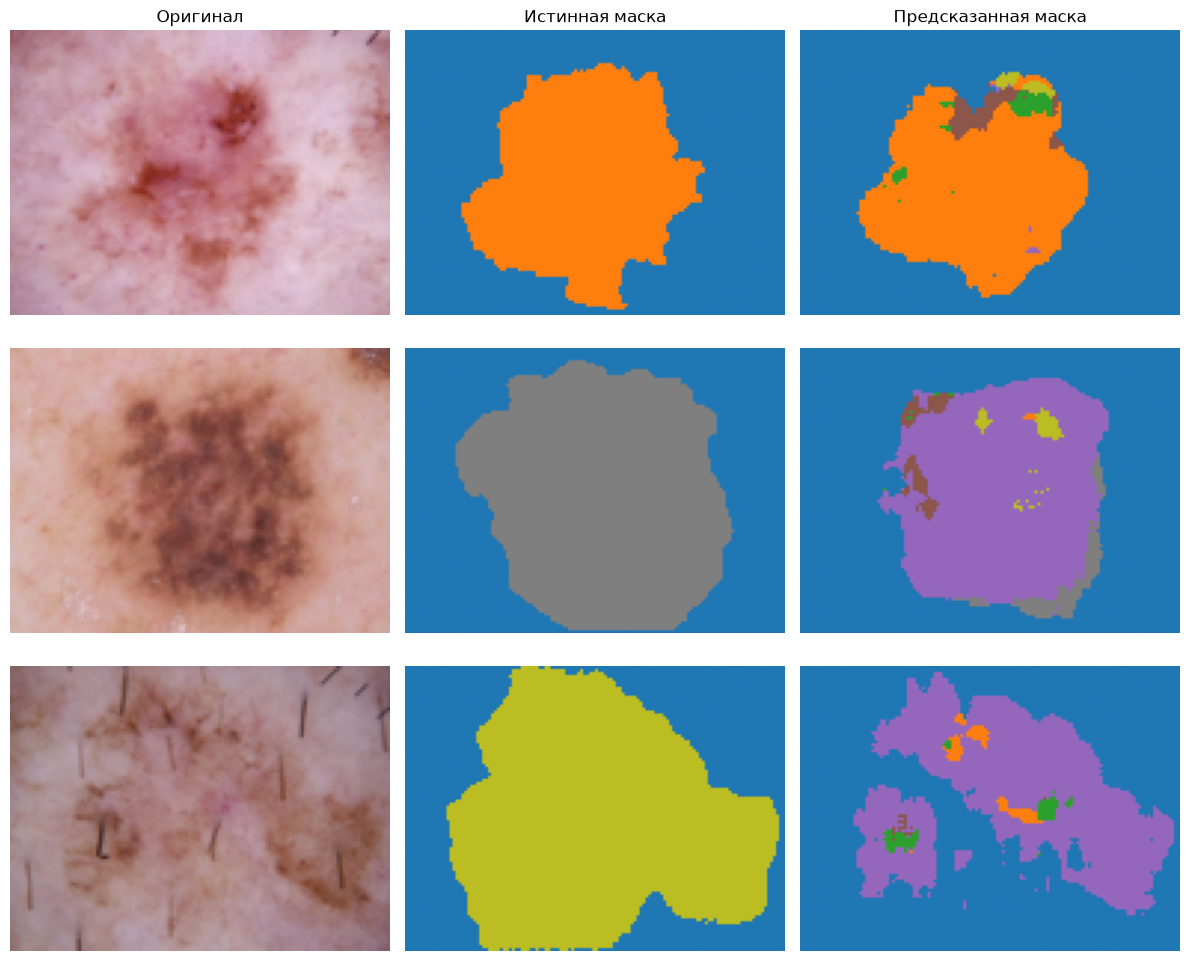

,image,class,IoU,FP,FN
0,ISIC_0024372.jpg,actinic keratoses,0.7581,92,974
1,ISIC_0024695.jpg,melanocytic nevi,0.0485,0,6037
2,ISIC_0024739.jpg,melanoma,0.0000,0,7448



Анализ ошибки:
Изображение: ISIC_0024739.jpg
Класс: melanoma
IoU: 0.0000
TP: 0
FP: 0
FN: 7448
Пропущено как фон: 3078
Перепутано с другим классом: 4370
Основной тип ошибки: Путаница диагностических классов


In [14]:
selected_classes = [1, 5, 6]

selected_indices = [
    int(val_used.index[
        val_used["class_index"] == cls
    ][0])
    for cls in selected_classes
]

model_baseline.eval()

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
examples_stats = []

with torch.no_grad():
    for row, idx in enumerate(selected_indices):
        image, true_mask, class_idx = val_dataset[idx]

        logits = model_baseline(
            image.unsqueeze(0).to(DEVICE)
        )

        pred_mask = (
            logits.argmax(dim=1)
            .squeeze(0)
            .cpu()
            .numpy()
        )

        true_np = true_mask.numpy()
        image_np = (
            (image * 0.5 + 0.5)
            .clamp(0, 1)
            .permute(1, 2, 0)
            .numpy()
        )

        axes[row, 0].imshow(image_np)
        axes[row, 1].imshow(
            true_np, cmap="tab10",
            vmin=0, vmax=NUM_CLASSES - 1
        )
        axes[row, 2].imshow(
            pred_mask, cmap="tab10",
            vmin=0, vmax=NUM_CLASSES - 1
        )

        class_name = CLASS_NAMES[class_idx - 1]
        axes[row, 0].set_ylabel(
            f"{class_name}", fontsize=10
        )

        for ax in axes[row]:
            ax.axis("off")

        # IoU диагностического класса изображения
        true_c = true_np == class_idx
        pred_c = pred_mask == class_idx

        tp = int((true_c & pred_c).sum())
        fp = int((~true_c & pred_c).sum())
        fn = int((true_c & ~pred_c).sum())

        union = tp + fp + fn
        sample_iou = tp / union if union > 0 else float("nan")

        # Уточняем, как именно ошиблась модель
        missed_bg = int(
            (true_c & (pred_mask == 0)).sum()
        )

        missed_other = int(
            (true_c & (pred_mask != 0) & ~pred_c).sum()
        )

        examples_stats.append({
            "image": val_used.iloc[idx]["img_name"],
            "class": class_name,
            "IoU": sample_iou,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "missed_bg": missed_bg,
            "missed_other": missed_other
        })

for ax, title in zip(
    axes[0],
    ["Оригинал", "Истинная маска", "Предсказанная маска"]
):
    ax.set_title(title)

plt.tight_layout()
plt.show()

# Количественный анализ выбранных изображений
stats_df = pd.DataFrame(examples_stats)
display(
    stats_df[["image", "class", "IoU", "FP", "FN"]].round(4)
)

# Разбираем пример с минимальным IoU
valid_examples = [
    e for e in examples_stats if not np.isnan(e["IoU"])
]

if valid_examples:
    worst = min(valid_examples, key=lambda e: e["IoU"])

    print("\nАнализ ошибки:")
    print(f"Изображение: {worst['image']}")
    print(f"Класс: {worst['class']}")
    print(f"IoU: {worst['IoU']:.4f}")
    print(f"TP: {worst['TP']}")
    print(f"FP: {worst['FP']}")
    print(f"FN: {worst['FN']}")
    print(f"Пропущено как фон: {worst['missed_bg']}")
    print(f"Перепутано с другим классом: {worst['missed_other']}")

    errors = {
        "Пропуск поражения (фон)": worst["missed_bg"],
        "Путаница диагностических классов": worst["missed_other"],
        "Ложноположительные пиксели": worst["FP"]
    }

    main_error = max(errors, key=errors.get)
    print(f"Основной тип ошибки: {main_error}")
